## 0 · Runtime check & installs


In [1]:
!pip install -q torchvision matplotlib seaborn scikit-learn tqdm


In [2]:
import sys
print('Python:', sys.version)
import torch, torchvision
print('PyTorch    :', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('CUDA avail :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU        :', torch.cuda.get_device_name(0))
from torchvision import models
_ = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
print('MobileNet-V2 loaded successfully!')


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch    : 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA avail : True
GPU        : Tesla T4
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 91.3MB/s]


MobileNet-V2 loaded successfully!


# MobileNet-V2 — PlantVillage Disease Classification (Google Colab)

| Phase | Trains | Optimizer | Learning rate | Schedule |
|---|---|---|---|---|
| 1 — Feature extraction | Compact classifier head | AdamW | 1e-3 | ReduceLROnPlateau |
| 2 — Fine-tuning | Classifier + top InvertedResidual blocks | AdamW | 1e-4 / 1e-5 | OneCycleLR |

MobileNet-V2 uses depthwise-separable convolutions organised into 18 `features` blocks (0 = stem, 1–17 = InvertedResidual stacks, 18 = last conv). Phase 1 trains only the classifier head with the backbone frozen; Phase 2 unfreezes `features[14:]` together with the head.

**Speed note:** On first run, the dataset is copied from Drive to Colab's local SSD in the background. The DataLoader starts reading from Drive immediately and switches to SSD automatically once the copy completes — no waiting before training begins.

**Checkpointing:** Full resumable checkpoints are saved to Google Drive after every completed epoch.  
Checkpoint folder: `MyDrive/AgroDetect/MobileNetV2/checkpoints/`

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os, json, shutil, time, copy, random, threading
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch, torch.nn as nn, torch.optim as optim, torchvision
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32       = True

# ── Paths ────────────────────────────────────────────────────────────────────
DRIVE_ROOT      = Path('/content/drive/MyDrive/AgroDetect')
DATA_SOURCE_DIR = DRIVE_ROOT / 'new_preprocess_dataset_plantvillage'
LOCAL_DATA_DIR  = Path('/content/new_preprocess_dataset_plantvillage')

if not DATA_SOURCE_DIR.is_dir():
    raise FileNotFoundError(f'Drive dataset folder not found: {DATA_SOURCE_DIR}')

OUTPUT_DIR     = DRIVE_ROOT / 'mobilenet_v2'
MODELS_DIR     = OUTPUT_DIR / 'models'
RESULTS_DIR    = OUTPUT_DIR / 'results'
CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
for d in (MODELS_DIR, RESULTS_DIR, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Hyperparameters ──────────────────────────────────────────────────────────
NUM_CLASSES        = 38
IMG_SIZE           = 224
BATCH_SIZE         = 128
ACCUMULATION_STEPS = 1
NUM_WORKERS        = 4   # bumped back up — will be used once local copy is ready
P1_EPOCHS          = 15
P1_LR              = 1e-3
P2_EPOCHS          = 15
P2_HEAD_LR         = 1e-4
P2_BACKBONE_LR     = 1e-5
LABEL_SMOOTHING    = 0.0
EARLY_STOP_PAT     = 5
UNFREEZE_FROM      = 14
RESUME             = True
USE_COMPILE        = False
WORKFLOW_VERSION   = 1

DEVICE            = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_CHANNELS_LAST = DEVICE.type == 'cuda'
USE_AMP           = DEVICE.type == 'cuda'
if hasattr(torch, 'set_float32_matmul_precision'):
    torch.set_float32_matmul_precision('high')
if DEVICE.type != 'cuda':
    raise RuntimeError('A CUDA runtime is required. Runtime > Change runtime type > T4 GPU.')

print('PyTorch    :', torch.__version__)
print('Device     :', DEVICE, '|', torch.cuda.get_device_name(0))
print('GPU mem    :', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GB')
print('Output dir :', OUTPUT_DIR)

PyTorch    : 2.14.1+cu130
Device     : cuda | Tesla T4
GPU mem    : 14.56 GB
Output dir : /content/drive/MyDrive/AgroDetect/mobilenet_v2


## Background SSD cache — start immediately, train in parallel

In [5]:
# ── Background copy: Drive → local SSD ──────────────────────────────────────
# Training starts from Drive right away. Once the copy finishes, DataLoaders
# are silently rebuilt to read from SSD. You get full speed with zero wait.

_local_ready   = threading.Event()   # set when local copy is complete
_copy_failed   = False

def _bg_copy():
    global _copy_failed
    flag = LOCAL_DATA_DIR / '.copy_complete'
    if flag.exists():
        print('[cache] Local SSD copy already exists — skipping copy.')
        _local_ready.set()
        return
    try:
        print('[cache] Background copy starting (Drive → SSD) …')
        shutil.copytree(DATA_SOURCE_DIR, LOCAL_DATA_DIR, dirs_exist_ok=True)
        flag.touch()
        print('[cache] Background copy complete ✓  DataLoaders will switch to SSD.')
        _local_ready.set()
    except Exception as exc:
        _copy_failed = True
        print(f'[cache] Background copy failed ({exc}). Continuing from Drive.')

_copy_thread = threading.Thread(target=_bg_copy, daemon=True)
_copy_thread.start()

# Use Drive for now; _get_data_dir() returns local path once copy is done
def _get_data_dir():
    return LOCAL_DATA_DIR if _local_ready.is_set() else DATA_SOURCE_DIR

DATA_DIR  = DATA_SOURCE_DIR   # initial
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR   = DATA_DIR / 'val'
TEST_DIR  = DATA_DIR / 'test'
for folder in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing: {folder}')
print('Dataset splits found on Drive ✓  Training will begin immediately.')

[cache] Background copy starting (Drive → SSD) …
Dataset splits found on Drive ✓  Training will begin immediately.


## 1 · Data loading

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def build_loaders(data_dir):
    """Build DataLoaders from data_dir (Drive or local SSD)."""
    d = Path(data_dir)
    tr = datasets.ImageFolder(d / 'train', transform=train_tf)
    vl = datasets.ImageFolder(d / 'val',   transform=eval_tf)
    te = datasets.ImageFolder(d / 'test',  transform=eval_tf)
    assert tr.classes == vl.classes == te.classes, 'Class mismatch across splits.'
    # Use 2 workers for Drive (FUSE bottleneck), 4 for local SSD
    nw = NUM_WORKERS if _local_ready.is_set() else 2
    kw = dict(batch_size=BATCH_SIZE, num_workers=nw, pin_memory=True,
              prefetch_factor=2, persistent_workers=(nw > 0), drop_last=True)
    return (
        DataLoader(tr, shuffle=True,  **kw),
        DataLoader(vl, shuffle=False, **kw),
        DataLoader(te, shuffle=False, **kw),
        tr.classes,
    )


train_loader, val_loader, test_loader, CLASS_NAMES = build_loaders(DATA_SOURCE_DIR)
assert len(CLASS_NAMES) == NUM_CLASSES, f'Expected {NUM_CLASSES} classes, got {len(CLASS_NAMES)}'

print(f'Train : {len(train_loader.dataset):,} images | {len(train_loader)} batches')
print(f'Val   : {len(val_loader.dataset):,} images | {len(val_loader)} batches')
print(f'Test  : {len(test_loader.dataset):,} images | {len(test_loader)} batches')
print(f'Workers: {train_loader.num_workers} (will rebuild to {NUM_WORKERS} once SSD copy finishes)')

Train : 30,412 images | 237 batches
Val   : 6,517 images | 50 batches
Test  : 6,515 images | 50 batches
Workers: 2 (will rebuild to 4 once SSD copy finishes)


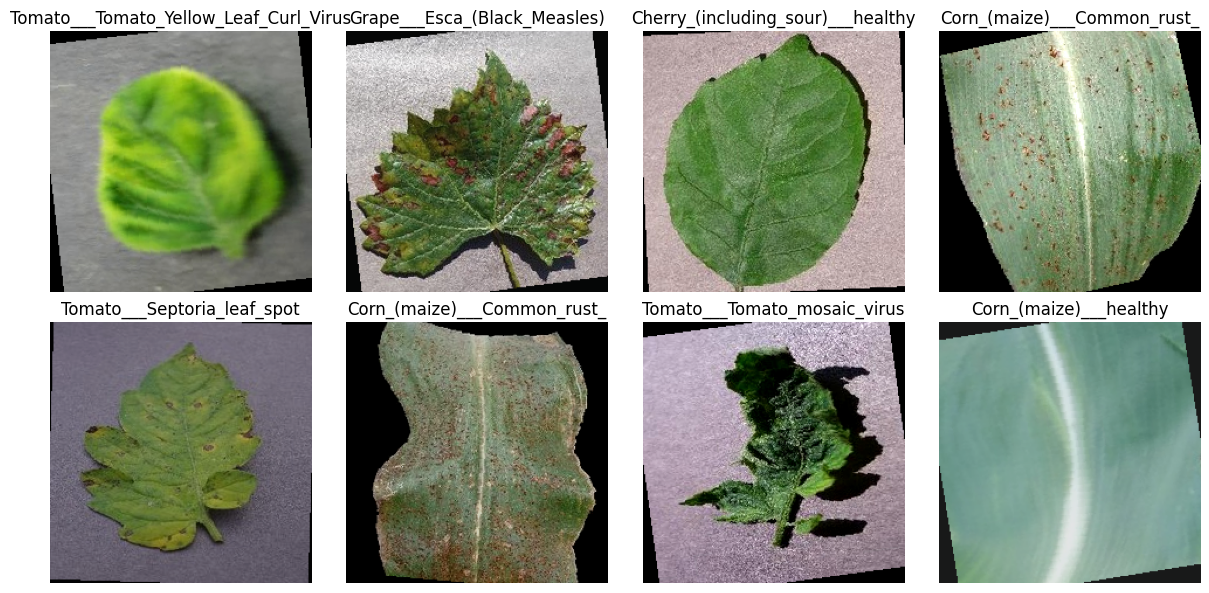

In [7]:
batch_images, batch_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, image, label in zip(axes.flat, batch_images[:8], batch_labels[:8]):
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image * np.asarray(IMAGENET_STD) + np.asarray(IMAGENET_MEAN), 0, 1)
    axis.imshow(image); axis.set_title(CLASS_NAMES[label]); axis.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'sample_images.png', dpi=100, bbox_inches='tight')
plt.show()

## 2 · Model definition

In [8]:
def build_mobilenet_v2(num_classes, freeze_base=True):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    in_features = model.classifier[1].in_features   # 1280
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.4),
        nn.Linear(256, num_classes),
    )
    if freeze_base:
        for p in model.features.parameters():
            p.requires_grad = False
    for p in model.classifier.parameters():
        p.requires_grad = True
    return model


def plain_model(model):
    return model._orig_mod if hasattr(model, '_orig_mod') else model


def count_params(model):
    base = plain_model(model)
    total     = sum(p.numel() for p in base.parameters())
    trainable = sum(p.numel() for p in base.parameters() if p.requires_grad)
    return trainable, total


model = build_mobilenet_v2(NUM_CLASSES, freeze_base=True)
trainable, total = count_params(model)
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')
if USE_COMPILE:
    model = torch.compile(model)
model = model.to(DEVICE)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

Trainable: 337,702 / 2,561,574 (13.2%)


## 3 · Training utilities

In [11]:
def capture_rng_state():
    state = {'torch_rng_state': torch.get_rng_state(),
             'numpy_rng_state': np.random.get_state()}
    if torch.cuda.is_available():
        state['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
    return state


def restore_rng_state(ckpt):
    torch.set_rng_state(ckpt['torch_rng_state'])
    np.random.set_state(ckpt['numpy_rng_state'])
    if torch.cuda.is_available() and 'cuda_rng_state_all' in ckpt:
        torch.cuda.set_rng_state_all(ckpt['cuda_rng_state_all'])


def save_checkpoint(path, model, optimizer, scheduler, scaler,
                    phase, epoch, history, best_val_acc, best_model_state):
    payload = {
        'workflow_version':      WORKFLOW_VERSION,
        'phase':                 phase,
        'epoch_completed':       epoch,
        'model_state_dict':      plain_model(model).state_dict(),
        'optimizer_state_dict':  optimizer.state_dict(),
        'scheduler_state_dict':  scheduler.state_dict() if scheduler else None,
        'scaler_state_dict':     scaler.state_dict() if scaler else None,
        'history':               history,
        'best_val_acc':          best_val_acc,
        'best_model_state_dict': best_model_state,
        **capture_rng_state(),
    }
    path = Path(path)
    tmp  = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, tmp)
    os.replace(tmp, path)
    print(f'  Checkpoint saved: {path.name} (epoch {epoch})')


def load_checkpoint(path, model, optimizer, scheduler=None, scaler=None):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    if ckpt.get('workflow_version') != WORKFLOW_VERSION:
        print(f'Incompatible checkpoint {path.name} — ignoring.')
        return None
    plain_model(model).load_state_dict(ckpt['model_state_dict'])
    optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    if scheduler is not None and ckpt.get('scheduler_state_dict'):
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])
    if scaler is not None and ckpt.get('scaler_state_dict'):
        scaler.load_state_dict(ckpt['scaler_state_dict'])
    restore_rng_state(ckpt)
    print(f"Resuming {ckpt['phase']} after epoch {ckpt['epoch_completed']}.")
    return ckpt


class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.counter, self.best_score, self.best_state, self.stop = 0, None, None, False

    def step(self, score, model):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = copy.deepcopy(plain_model(model).state_dict())
            self.counter    = 0
            return True
        self.counter += 1
        if self.counter >= self.patience:
            self.stop = True
        return False


def train_one_epoch(model, loader, criterion, optimizer, scaler, scheduler=None):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    for i, (images, labels) in enumerate(tqdm(loader, leave=False, desc='train')):
        images = images.to(DEVICE, non_blocking=True,
                           memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels) / ACCUMULATION_STEPS
        scaler.scale(loss).backward()
        if (i + 1) % ACCUMULATION_STEPS == 0 or i + 1 == len(loader):
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
            if scheduler is not None:
                scheduler.step()
        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        correct += (logits.detach().argmax(1) == labels).sum().item()
        total += images.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False, desc='eval'):
        images = images.to(DEVICE, non_blocking=True,
                           memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format)
        labels = labels.to(DEVICE, non_blocking=True)
        with autocast('cuda', enabled=USE_AMP):
            logits = model(images)
            loss   = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct      += (logits.argmax(1) == labels).sum().item()
        total        += labels.size(0)
    return running_loss / total, correct / total


def maybe_switch_to_ssd(current_loaders):
    """Rebuild DataLoaders from local SSD if copy just finished."""
    if _local_ready.is_set() and str(current_loaders[0].dataset.root).startswith(str(DATA_SOURCE_DIR)):
        print('[cache] Switching DataLoaders to local SSD …')
        return build_loaders(LOCAL_DATA_DIR)
    return (*current_loaders, CLASS_NAMES)


def run_phase(model, train_loader, val_loader, criterion, optimizer, scheduler,
              epochs, phase_name, checkpoint_path, scheduler_per_batch=False):
    scaler         = GradScaler('cuda', enabled=USE_AMP)
    history        = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    es             = EarlyStopping(patience=EARLY_STOP_PAT)
    start_epoch    = 1
    checkpoint_path = Path(checkpoint_path)

    if RESUME and checkpoint_path.exists():
        ckpt = load_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler)
        if ckpt is not None and ckpt.get('phase') == phase_name:
            history     = ckpt['history']
            start_epoch = int(ckpt['epoch_completed']) + 1
            es.best_score = ckpt.get('best_val_acc')
            es.best_state = ckpt.get('best_model_state_dict')
        elif ckpt is not None:
            print(f"Checkpoint is for {ckpt.get('phase')}; starting {phase_name} fresh.")

    for epoch in range(start_epoch, epochs + 1):
        # Switch to SSD mid-training if copy just finished
        new = maybe_switch_to_ssd((train_loader, val_loader))
        train_loader, val_loader = new[0], new[1]

        t0 = time.time()
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler,
            scheduler if scheduler_per_batch else None,
        )
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        if scheduler is not None and not scheduler_per_batch:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = es.step(val_acc, model)
        save_checkpoint(checkpoint_path, model, optimizer, scheduler, scaler,
                        phase_name, epoch, history, es.best_score, es.best_state)

        flag = ' ✓ best' if improved else f' ({es.counter}/{es.patience})'
        print(f'[{phase_name}] Epoch {epoch}/{epochs} | '
              f'loss {train_loss:.4f}/{val_loss:.4f} | '
              f'acc {train_acc:.4f}/{val_acc:.4f} | '
              f'{time.time() - t0:.1f}s{flag}')
        if es.stop:
            print(f'Early stopping at epoch {epoch}.')
            break

    if es.best_state is not None:
        plain_model(model).load_state_dict(es.best_state)
    print(f'[{phase_name}] Best val_acc = {es.best_score:.4f}')
    return history, train_loader, val_loader

## 4 · Phase 1 — Feature extraction

In [12]:
print('=' * 60)
print('PHASE 1 — Feature extraction (compact head only)')
print('=' * 60)

criterion    = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer_p1 = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=P1_LR, weight_decay=1e-4,
)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_p1, mode='min', patience=2, factor=0.2
)
history_p1, train_loader, val_loader = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p1, scheduler_p1,
    epochs=P1_EPOCHS, phase_name='P1',
    checkpoint_path=CHECKPOINT_DIR / 'phase1_latest.pt',
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'mobilenet_v2_phase1.pth')
print('Phase 1 weights saved.')

PHASE 1 — Feature extraction (compact head only)
Resuming P1 after epoch 3.
[cache] Switching DataLoaders to local SSD …


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


train:   0%|          | 0/237 [00:00<?, ?it/s]

eval:   0%|          | 0/50 [00:00<?, ?it/s]

  Checkpoint saved: phase1_latest.pt (epoch 4)
[P1] Epoch 4/15 | loss 0.2587/0.1336 | acc 0.9184/0.9591 | 149.8s ✓ best


train:   0%|          | 0/237 [00:00<?, ?it/s]

... (28 outputs left out)

  Checkpoint saved: phase1_latest.pt (epoch 14)
[P1] Epoch 14/15 | loss 0.1731/0.0880 | acc 0.9419/0.9711 | 143.0s (1/5)


train:   0%|          | 0/237 [00:00<?, ?it/s]

eval:   0%|          | 0/50 [00:00<?, ?it/s]

  Checkpoint saved: phase1_latest.pt (epoch 15)
[P1] Epoch 15/15 | loss 0.1715/0.0870 | acc 0.9404/0.9705 | 142.6s (2/5)
[P1] Best val_acc = 0.9722
Phase 1 weights saved.


## 5 · Phase 2 — Fine-tuning (`features[14:]` + classifier)

Unfreezes the top 5 InvertedResidual blocks (14–18) together with the head.

In [14]:
base = plain_model(model)

for p in base.parameters():
    p.requires_grad = False
for p in base.features[UNFREEZE_FROM:].parameters():
    p.requires_grad = True
for p in base.classifier.parameters():
    p.requires_grad = True

trainable, total = count_params(model)
print(f'Unfrozen: features[{UNFREEZE_FROM}:] + classifier')
print(f'Trainable: {trainable:,} / {total:,} ({100 * trainable / total:.1f}%)')

Unfrozen: features[14:] + classifier
Trainable: 2,019,046 / 2,561,574 (78.8%)


In [15]:
print('=' * 60)
print(f'PHASE 2 — Fine-tuning MobileNet-V2 features[{UNFREEZE_FROM}:] + classifier')
print('=' * 60)

optimizer_p2 = optim.AdamW([
    {'params': base.features[UNFREEZE_FROM:].parameters(), 'lr': P2_BACKBONE_LR},
    {'params': base.classifier.parameters(),               'lr': P2_HEAD_LR},
], weight_decay=1e-4)

steps_per_epoch = len(train_loader)   # already accounts for drop_last
scheduler_p2 = optim.lr_scheduler.OneCycleLR(
    optimizer_p2,
    max_lr=[P2_BACKBONE_LR, P2_HEAD_LR],
    steps_per_epoch=steps_per_epoch,
    epochs=P2_EPOCHS,
    pct_start=0.2,
    anneal_strategy='cos',
)
history_p2, train_loader, val_loader = run_phase(
    model, train_loader, val_loader, criterion, optimizer_p2, scheduler_p2,
    epochs=P2_EPOCHS, phase_name='P2',
    checkpoint_path=CHECKPOINT_DIR / 'phase2_latest.pt',
    scheduler_per_batch=True,
)
torch.save(plain_model(model).state_dict(), MODELS_DIR / 'mobilenet_v2_best.pth')
print('Best fine-tuned weights saved.')

PHASE 2 — Fine-tuning MobileNet-V2 features[14:] + classifier


train:   0%|          | 0/237 [00:00<?, ?it/s]

eval:   0%|          | 0/50 [00:00<?, ?it/s]

  Checkpoint saved: phase2_latest.pt (epoch 1)
[P2] Epoch 1/15 | loss 0.1715/0.0785 | acc 0.9418/0.9736 | 149.9s ✓ best


train:   0%|          | 0/237 [00:00<?, ?it/s]

eval:   0%|          | 0/50 [00:00<?, ?it/s]

... (36 outputs left out)

  Checkpoint saved: phase2_latest.pt (epoch 14)
[P2] Epoch 14/15 | loss 0.0832/0.0485 | acc 0.9714/0.9834 | 140.2s (1/5)


train:   0%|          | 0/237 [00:00<?, ?it/s]

eval:   0%|          | 0/50 [00:00<?, ?it/s]

  Checkpoint saved: phase2_latest.pt (epoch 15)
[P2] Epoch 15/15 | loss 0.0798/0.0493 | acc 0.9744/0.9833 | 141.4s (2/5)
[P2] Best val_acc = 0.9838
Best fine-tuned weights saved.


## 6 · Training curves

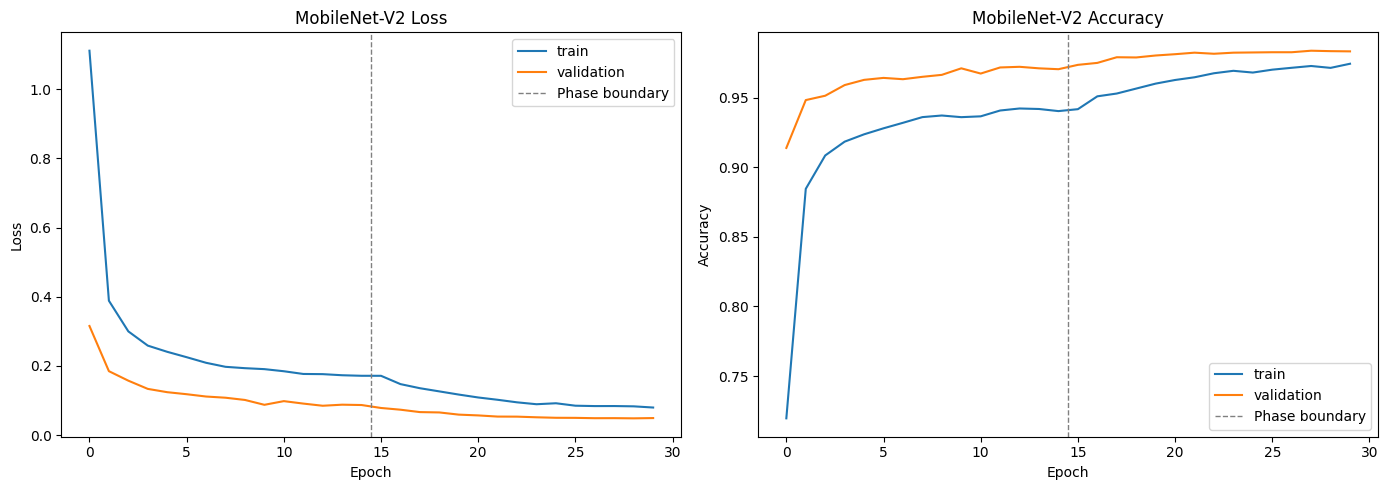

In [16]:
def combined_history(key):
    return history_p1[key] + history_p2[key]

p1_len = len(history_p1['train_loss'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['loss', 'acc'], ['Loss', 'Accuracy']):
    ax.plot(combined_history(f'train_{metric}'), label='train')
    ax.plot(combined_history(f'val_{metric}'),   label='validation')
    ax.axvline(p1_len - 0.5, color='gray', linestyle='--', linewidth=1, label='Phase boundary')
    ax.set(title=f'MobileNet-V2 {title}', xlabel='Epoch', ylabel=title)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7 · Test evaluation

In [17]:
# Wait for SSD copy before test inference (optional — just faster)
if not _local_ready.is_set():
    print('Waiting for SSD copy to finish before test run …')
    _copy_thread.join(timeout=600)
_, _, test_loader, _ = build_loaders(_get_data_dir())

model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='test', leave=False):
        logits = model(images.to(DEVICE, non_blocking=True,
                                 memory_format=torch.channels_last if USE_CHANNELS_LAST else torch.preserve_format))
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

test_acc = accuracy_score(y_true, y_pred)
test_f1  = f1_score(y_true, y_pred, average='macro')
report   = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
(RESULTS_DIR / 'classification_report.txt').write_text(report, encoding='utf-8')
print(report)
print(f'Test accuracy : {test_acc:.4f}')
print(f'Test macro F1 : {test_f1:.4f}')

test:   0%|          | 0/50 [00:00<?, ?it/s]

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.96      1.00      0.98        75
                                 Apple___Black_rot       1.00      1.00      1.00        75
                          Apple___Cedar_apple_rust       1.00      0.97      0.98        33
                                   Apple___healthy       1.00      0.98      0.99       198
                               Blueberry___healthy       0.99      1.00      1.00       181
          Cherry_(including_sour)___Powdery_mildew       1.00      0.99      1.00       127
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       102
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.93      0.85      0.89        61
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       143
               Corn_(maize)___Northern_Leaf_Blight       0.93      0.97      0.

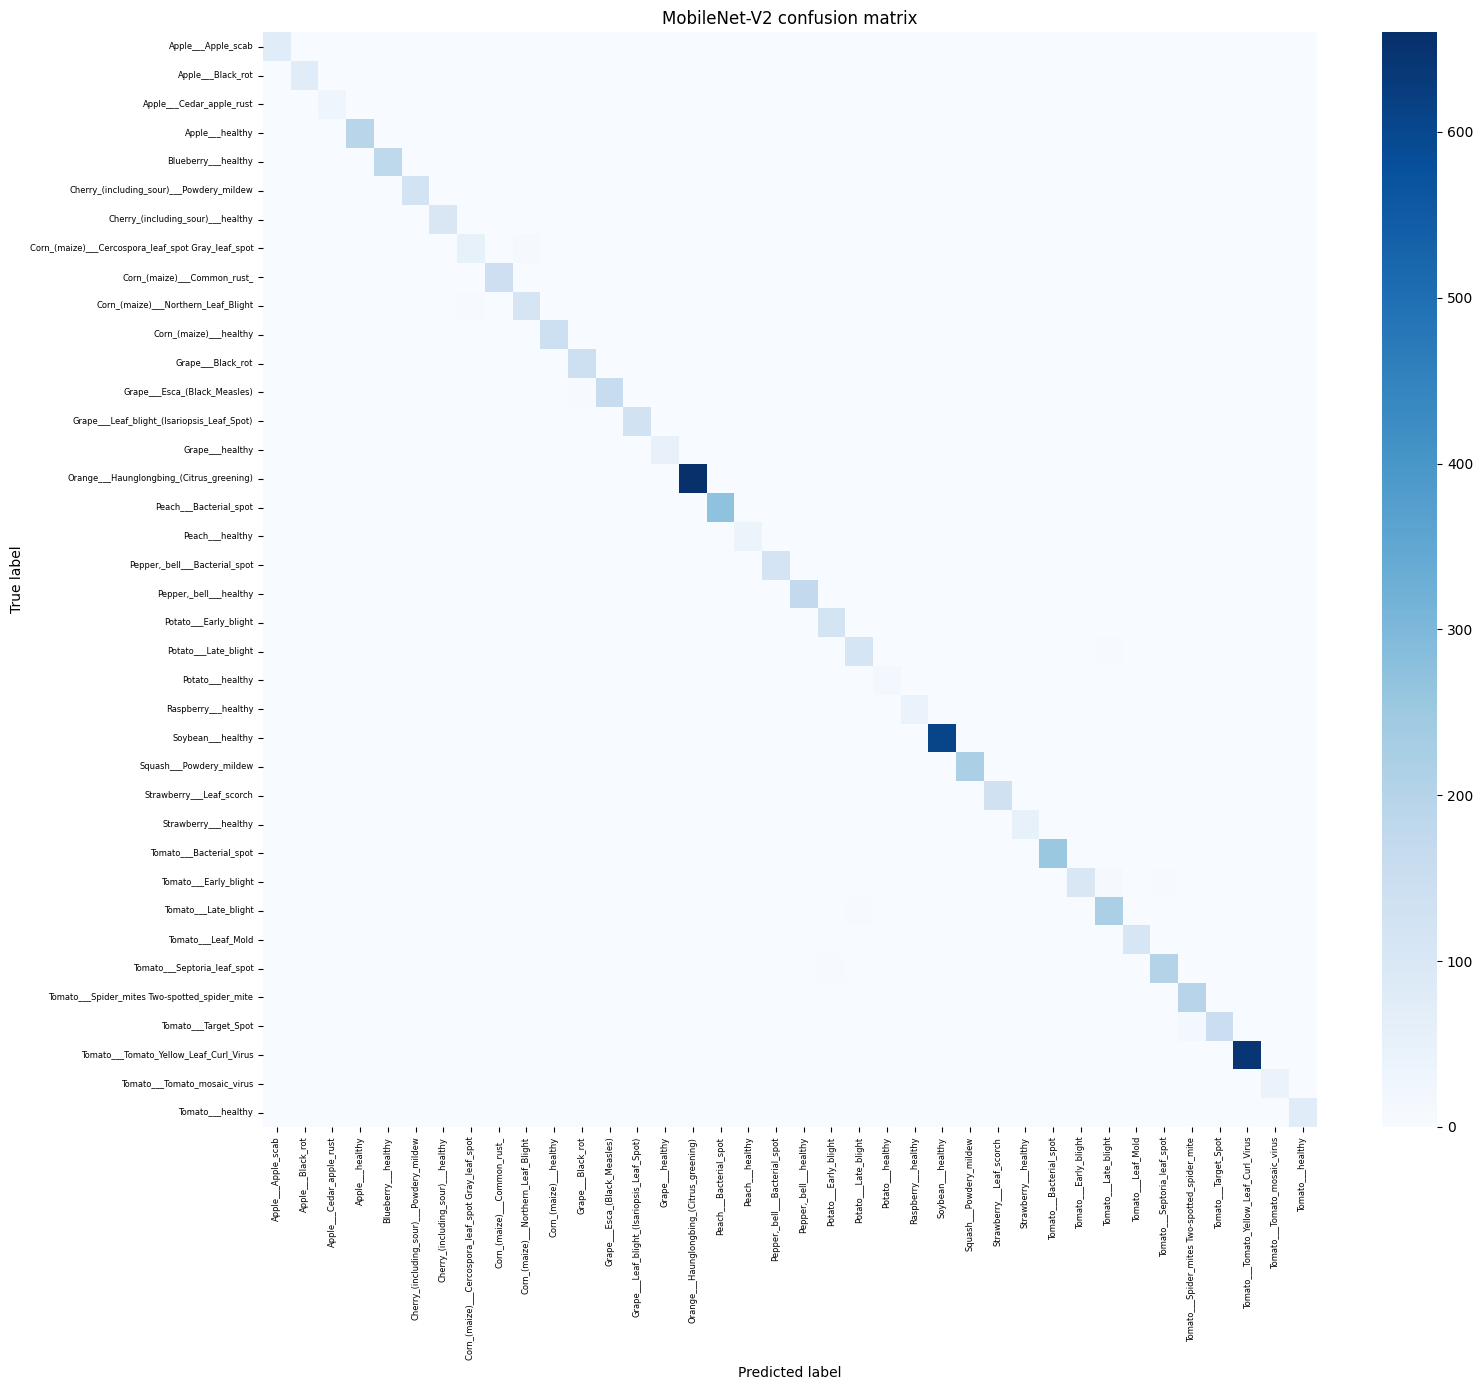

In [18]:
cm = confusion_matrix(y_true, y_pred)
fig, axis = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, cmap='Blues', ax=axis, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axis.set(title='MobileNet-V2 confusion matrix', xlabel='Predicted label', ylabel='True label')
plt.xticks(rotation=90, fontsize=6); plt.yticks(fontsize=6)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

In [19]:
metrics = {
    'model':       'MobileNet-V2',
    'num_classes': NUM_CLASSES,
    'batch_size':  BATCH_SIZE,
    'amp':         USE_AMP,
    'checkpoint_policy': 'Google Drive checkpoint after every completed epoch; resumable',
    'test_accuracy': round(float(test_acc), 6),
    'test_f1_macro': round(float(test_f1),  6),
    'phase1': {
        'epochs_run':      len(history_p1['val_acc']),
        'max_epochs':      P1_EPOCHS,
        'lr':              P1_LR,
        'best_val_acc':    round(float(max(history_p1['val_acc'])), 6),
        'final_train_acc': round(float(history_p1['train_acc'][-1]), 6),
    },
    'phase2': {
        'epochs_run':          len(history_p2['val_acc']),
        'max_epochs':          P2_EPOCHS,
        'head_lr':             P2_HEAD_LR,
        'backbone_lr':         P2_BACKBONE_LR,
        'unfreeze_from_block': UNFREEZE_FROM,
        'scheduler':           'OneCycleLR (pct_start=0.2, cosine anneal)',
        'best_val_acc':        round(float(max(history_p2['val_acc'])), 6),
        'final_train_acc':     round(float(history_p2['train_acc'][-1]), 6),
    },
    'classes':          CLASS_NAMES,
    'training_history': {'phase1': history_p1, 'phase2': history_p2},
}
(RESULTS_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
summary = {k: v for k, v in metrics.items()
           if k not in ('classes', 'training_history')}
print(json.dumps(summary, indent=2))


{
  "model": "MobileNet-V2",
  "num_classes": 38,
  "batch_size": 128,
  "amp": true,
  "checkpoint_policy": "Google Drive checkpoint after every completed epoch; resumable",
  "test_accuracy": 0.982812,
  "test_f1_macro": 0.975905,
  "phase1": {
    "epochs_run": 15,
    "max_epochs": 15,
    "lr": 0.001,
    "best_val_acc": 0.972187,
    "final_train_acc": 0.940368
  },
  "phase2": {
    "epochs_run": 15,
    "max_epochs": 15,
    "head_lr": 0.0001,
    "backbone_lr": 1e-05,
    "unfreeze_from_block": 14,
    "scheduler": "OneCycleLR (pct_start=0.2, cosine anneal)",
    "best_val_acc": 0.98375,
    "final_train_acc": 0.974387
  }
}


In [27]:
print("MODELS_DIR exists:", MODELS_DIR.exists())
print("RESULTS_DIR exists:", RESULTS_DIR.exists())

# Check if the .pth files are anywhere
import subprocess
result = subprocess.run(['find', '/content/drive/MyDrive/AgroDetect/mobilenet_v2', '-type', 'f'],
                       capture_output=True, text=True)
print(result.stdout or "Nothing found")

MODELS_DIR exists: True
RESULTS_DIR exists: True
/content/drive/MyDrive/AgroDetect/mobilenet_v2/results/sample_images.png
/content/drive/MyDrive/AgroDetect/mobilenet_v2/results/training_curves.png
/content/drive/MyDrive/AgroDetect/mobilenet_v2/results/classification_report.txt
/content/drive/MyDrive/AgroDetect/mobilenet_v2/results/confusion_matrix.png
/content/drive/MyDrive/AgroDetect/mobilenet_v2/results/metrics.json
/content/drive/MyDrive/AgroDetect/mobilenet_v2/checkpoints/phase1_latest.pt
/content/drive/MyDrive/AgroDetect/mobilenet_v2/checkpoints/phase2_latest.pt



In [28]:
import os
for root, dirs, files in os.walk('/content'):
    for f in files:
        if f.endswith('.pth'):
            p = os.path.join(root, f)
            print(p, f'({os.path.getsize(p)/1e6:.1f} MB)')

/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-1075/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-2150/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-3225/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-1025/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-2050/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-3075/rng_state.pth (0.0 MB)
/content/drive/.shortcut-targets-by-id/1IEcKXy_TIbE_FpKBqIc9BIV1FxZfgler/Phishing_Email/models/distilbert/checkpoint-100/rng_state

## 8 · Copy results to Google Drive


In [34]:
import shutil

# Resolve the real Drive path (handles both MyDrive and shortcut-mounted folders)
_candidates = [
    Path('/content/drive/MyDrive/AgroDetect'),
    *sorted(Path('/content/drive/.shortcut-targets-by-id').glob('*/AgroDetect'))
]
REAL_AGRODETECT = next((p for p in _candidates if p.exists()), None)
if REAL_AGRODETECT is None:
    raise RuntimeError('Cannot find AgroDetect on Drive — is Drive mounted?')

DRIVE_OUT = REAL_AGRODETECT / 'mobilenet_v2'
DRIVE_MODELS_DIR     = DRIVE_OUT / 'models'
DRIVE_RESULTS_DIR    = DRIVE_OUT / 'results'
DRIVE_CHECKPOINT_DIR = DRIVE_OUT / 'checkpoints'

for d in (DRIVE_MODELS_DIR, DRIVE_RESULTS_DIR, DRIVE_CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Drive output root : {DRIVE_OUT}')

for src, dst in [
    (MODELS_DIR,     DRIVE_MODELS_DIR),
    (RESULTS_DIR,    DRIVE_RESULTS_DIR),
    (CHECKPOINT_DIR, DRIVE_CHECKPOINT_DIR),
]:
    if not src.exists():
        print(f'  Skipping {src.name}/ — not created yet.')
        continue
    for f in src.iterdir():
        target = dst / f.name
        if target.exists():
            print(f'  {src.name}/{f.name} — already exists, skipping.')
            continue
        shutil.copy2(f, target)
        print(f'  {src.name}/{f.name} copied ✓')

print('\nFiles on Drive:')
for p in sorted(DRIVE_OUT.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(DRIVE_OUT)} ({p.stat().st_size/1e6:.2f} MB)')

Drive output root : /content/drive/MyDrive/AgroDetect/mobilenet_v2
  results/sample_images.png — already exists, skipping.
  results/training_curves.png — already exists, skipping.
  results/classification_report.txt — already exists, skipping.
  results/confusion_matrix.png — already exists, skipping.
  results/metrics.json — already exists, skipping.
  checkpoints/phase1_latest.pt — already exists, skipping.
  checkpoints/phase2_latest.pt — already exists, skipping.

Files on Drive:
  checkpoints/phase1_latest.pt (23.71 MB)
  checkpoints/phase2_latest.pt (37.19 MB)
  results/classification_report.txt (0.00 MB)
  results/confusion_matrix.png (0.18 MB)
  results/metrics.json (0.01 MB)
  results/sample_images.png (1.03 MB)
  results/training_curves.png (0.07 MB)


In [35]:
print('Files on Drive:')
for p in sorted(DRIVE_OUT.rglob('*')):
    if p.is_file():
        print(f'  {p.relative_to(DRIVE_OUT)} ({p.stat().st_size/1e6:.2f} MB)')

Files on Drive:
  checkpoints/phase1_latest.pt (23.71 MB)
  checkpoints/phase2_latest.pt (37.19 MB)
  results/classification_report.txt (0.00 MB)
  results/confusion_matrix.png (0.18 MB)
  results/metrics.json (0.01 MB)
  results/sample_images.png (1.03 MB)
  results/training_curves.png (0.07 MB)


## Summary

| Phase | Trainable layers | Optimizer | Learning rate | Scheduler |
|---|---|---|---|---|
| Phase 1 | Classifier head | AdamW | 1e-3 | ReduceLROnPlateau |
| Phase 2 | features[14:] + classifier | AdamW | 1e-5 / 1e-4 | OneCycleLR per step |

Checkpoints: `MyDrive/AgroDetect/MobileNetV2/checkpoints/`  
Best weights: `MyDrive/AgroDetect/MobileNetV2/models/mobilenet_v2_best.pth`